# 07 GLASS Dedicated Pair Plots

Build publication-count/SI plots and category-driver plots only for GLASS pathogen-antibiotic pairs with available SI data.

## Inputs

- Screened yearly pairs and yearly SI data from notebooks 04c and 05.
- GLASS pair data, prediction/category records, and configured pathogen/antibiotic/driver lookup tables.

## Outputs

- Dedicated longitudinal SI and driver-category plots for eligible GLASS pairs under `outputs/figures/`.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines import (
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_si_and_clean_glass_list,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    save_category_driver_plots,
    save_interesting_si_plots,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Parameters

In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
FIGURE_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ASSETS_DIR = cfg_path(PIPELINE_CONFIG, "paths.assets_dir", PROJECT_ROOT)
YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

GLASS_XLSX_PATH = cfg_path(PIPELINE_CONFIG, "paths.glass_xlsx", PROJECT_ROOT)
GLASS_CLEANED_PATH = cfg_path(PIPELINE_CONFIG, "paths.glass_cleaned", PROJECT_ROOT)
BACTERIA_SYNONYM_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogens", PROJECT_ROOT)
ANTIBIOTIC_SYNONYM_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_synonyms", PROJECT_ROOT)

ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "glass_plots.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
GLASS_SI_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_plots"
GLASS_DRIVER_PLOT_DIR = FIGURE_OUTPUT_DIR / "glass_yearly_si_driver_plots"

# Reuse SI fit window settings so GLASS plots stay aligned with notebook 05 outputs.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "glass_plots.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS
MIN_TOTAL_AMR_PUBLICATIONS = cfg(PIPELINE_CONFIG, "glass_plots.min_tot_amr_publications")
MIN_AMR_PAIR_PUBLICATION_COUNT = cfg(PIPELINE_CONFIG, "si.min_amr_pair_publication_count")
MIN_NUM_YEARS_WITH_VALID_COUNTS = cfg(PIPELINE_CONFIG, "si.min_num_years_with_valid_counts")

LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")

CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "glass_plots.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "glass_plots.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "glass_plots.driver_lookback_years")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "glass_plots.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.max_display_plots")
MAX_GLASS_PLOTS = cfg(PIPELINE_CONFIG, "glass_plots.max_glass_plots")


## Load Inputs

In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)

yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_total_amr_publications=MIN_TOTAL_AMR_PUBLICATIONS,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)
display(pathogen_filter_summary_df.query("status != 'present_in_both'"))

if not YEARLY_SCREENED_PATH.exists():
    raise FileNotFoundError(
        f"Missing {YEARLY_SCREENED_PATH}. Run notebook 04 to create screened AMR pairs first."
    )

si_cache_is_fresh = YEARLY_SI_PATH.exists() and YEARLY_SI_PATH.stat().st_mtime >= YEARLY_SCREENED_PATH.stat().st_mtime
if si_cache_is_fresh:
    si_df = pd.read_parquet(YEARLY_SI_PATH)
    cached_threshold = si_df.get("min_amr_pair_publication_count", pd.Series(dtype=float))
    cached_threshold = float(cached_threshold.dropna().iloc[0]) if not cached_threshold.dropna().empty else None
    si_cache_is_fresh = cached_threshold == float(MIN_AMR_PAIR_PUBLICATION_COUNT)
    if si_cache_is_fresh:
        print(f"Loaded SI rows: {len(si_df):,} from {YEARLY_SI_PATH}")
    else:
        print("Rebuilding SI because min_amr_pair_publication_count changed.")
if not si_cache_is_fresh:
    if YEARLY_SI_PATH.exists():
        print(f"Rebuilding SI because the cached output is stale or its threshold differs from the configured value.")
    si_df, pooled_model, design_columns = build_yearly_si_dataset(
        yearly_screened_model_df,
        pathogen_bg_df,
        antibiotic_bg_model_df,
        min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
        output_path=YEARLY_SI_PATH,
    )
    print(f"Built SI rows: {len(si_df):,} and saved to {YEARLY_SI_PATH}")

si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))

_, glass_pairs_df = load_si_and_clean_glass_list(
    YEARLY_SI_PATH,
    GLASS_XLSX_PATH,
    bacteria_synonym_path=BACTERIA_SYNONYM_PATH,
    antibiotic_synonym_path=ANTIBIOTIC_SYNONYM_PATH,
    antibiotic_coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    glass_cleaned_path=GLASS_CLEANED_PATH,
)

display(glass_pairs_df.head())


yearly_screened rows: 64,721
yearly_screened unique pathogens: 719
yearly_screened unique antibiotics: 213
yearly_screened year range: 2000 - 2026
pathogen bg rows: 21,330
antibiotic bg rows: 5,886
unified decision rows available for driver analysis: 186,724
Antibiotic analysis level: individual antibiotic.
model yearly rows: 64,721
model pathogen-antibiotic rows: 15,539
model antibiotic values: 213
model antibiotic background rows: 5,886
model unified decision rows: 186,724
AMR publication filter: kept 909 / 15,539 pairs with >= 30 total publications from 2000 to 2023.
model input before publication filter pathogens: 719
model input after publication filter pathogens: 77
Pathogens present in model input before publication filter but absent from model input after publication filter: 642
Abiotrophia defectiva, Achromobacter denitrificans, Achromobacter mucicolens, Achromobacter xylosoxidans, Acinetobacter bereziniae, Acinetobacter calcoaceticus, Acinetobacter haemolyticus, Acinetobacter

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Abiotrophia defectiva,50,53,23,0.0,0.0,0.0,True,False,missing_from_modeled
1,Achromobacter denitrificans,10,10,7,0.0,0.0,0.0,True,False,missing_from_modeled
2,Achromobacter mucicolens,16,16,15,0.0,0.0,0.0,True,False,missing_from_modeled
3,Achromobacter xylosoxidans,270,382,60,0.0,0.0,0.0,True,False,missing_from_modeled
4,Acinetobacter bereziniae,19,19,12,0.0,0.0,0.0,True,False,missing_from_modeled
...,...,...,...,...,...,...,...,...,...,...
637,Winkia neuii,11,11,11,0.0,0.0,0.0,True,False,missing_from_modeled
638,Wohlfahrtiimonas chitiniclastica,17,17,13,0.0,0.0,0.0,True,False,missing_from_modeled
639,Yersinia pestis,85,106,30,0.0,0.0,0.0,True,False,missing_from_modeled
640,Yersinia pseudotuberculosis,87,89,33,0.0,0.0,0.0,True,False,missing_from_modeled


Loaded SI rows: 15,806 from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
filtered model input pathogens: 77
yearly SI output pathogens: 58
Pathogens present in filtered model input but absent from yearly SI output: 19
Aeromonas hydrophila, Bacillus anthracis, Corynebacterium striatum, Enterococcus durans, Enterococcus hirae, Francisella tularensis, Lactococcus lactis, Mycobacterium chelonae, Mycobacterium fortuitum, Mycobacterium kansasii, Nocardia farcinica, Porphyromonas gingivalis, Rhodococcus equi, Shigella dysenteriae, Staphylococcus hominis, Staphylococcus intermedius, Staphylococcus lugdunensis, Streptococcus dysgalactiae, Streptococcus uberis


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Aeromonas hydrophila,95,203,5,0.0,0.0,0.0,True,False,missing_from_modeled
1,Bacillus anthracis,20,43,1,0.0,0.0,0.0,True,False,missing_from_modeled
2,Corynebacterium striatum,17,42,1,0.0,0.0,0.0,True,False,missing_from_modeled
3,Enterococcus durans,18,37,1,0.0,0.0,0.0,True,False,missing_from_modeled
4,Enterococcus hirae,19,38,1,0.0,0.0,0.0,True,False,missing_from_modeled
5,Francisella tularensis,19,32,1,0.0,0.0,0.0,True,False,missing_from_modeled
6,Lactococcus lactis,19,39,1,0.0,0.0,0.0,True,False,missing_from_modeled
7,Mycobacterium chelonae,23,43,1,0.0,0.0,0.0,True,False,missing_from_modeled
8,Mycobacterium fortuitum,68,126,3,0.0,0.0,0.0,True,False,missing_from_modeled
9,Mycobacterium kansasii,21,40,1,0.0,0.0,0.0,True,False,missing_from_modeled


Loaded SI rows: 15,806 from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet
Pathogens: 58; antibiotics/levels: 96
Saved cleaned GLASS rows: 96 to /Users/f.costa/Code/Antimicrobial-Resistance/assets/glass_amr_cleaned.csv


,raw_pathogen,raw_antibiotic,pathogen,antibiotic,pathogen_standardized,antibiotic_standardized,Class,Simplified categories,High level categories,Origin
0,Acinetobacter spp.,amikacin,Acinetobacter baumannii,Amikacin,True,True,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
1,Acinetobacter spp.,Colistin,Acinetobacter baumannii,Colistin,True,False,Polymyxins,Miscellaneous,Other,Naturally occurring/modified
2,Acinetobacter spp.,doripenem,Acinetobacter baumannii,Doripenem,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified
3,Acinetobacter spp.,Gentamicin,Acinetobacter baumannii,Gentamicin,True,False,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
4,Acinetobacter spp.,Imipenem,Acinetobacter baumannii,Imipenem/cilastatin,True,True,Carbapenems,Penems/Carbapenems,Beta lactam and related,Naturally occurring/modified


## Keep GLASS Pairs With SI Data

In [5]:
si_pairs_df = si_df[["pathogen", "antibiotic"]].drop_duplicates()
glass_candidate_pairs_df = glass_pairs_df[["pathogen", "antibiotic"]].drop_duplicates()

glass_available_pairs_df = (
    glass_candidate_pairs_df.merge(si_pairs_df, on=["pathogen", "antibiotic"], how="inner")
    .sort_values(["pathogen", "antibiotic"])
    .reset_index(drop=True)
)

latest_counts_df = (
    si_df.sort_values("year")
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .tail(1)[["pathogen", "antibiotic", "year", "count", "SI"]]
    .rename(columns={"year": "latest_year", "count": "latest_count", "SI": "latest_SI"})
)

glass_plot_pairs_df = (
    glass_available_pairs_df.merge(latest_counts_df, on=["pathogen", "antibiotic"], how="left")
    .sort_values(["latest_count", "pathogen", "antibiotic"], ascending=[False, True, True])
    .reset_index(drop=True)
)
if MAX_GLASS_PLOTS is not None:
    glass_plot_pairs_df = glass_plot_pairs_df.head(int(MAX_GLASS_PLOTS)).copy()

print(f"GLASS candidate pairs: {len(glass_candidate_pairs_df):,}")
print(f"GLASS pairs with SI data: {len(glass_available_pairs_df):,}")
print(f"GLASS pairs selected for plotting: {len(glass_plot_pairs_df):,}")
display(glass_plot_pairs_df.head(30))

GLASS candidate pairs: 96
GLASS pairs with SI data: 80
GLASS pairs selected for plotting: 80


,pathogen,antibiotic,latest_year,latest_count,latest_SI
0,Escherichia coli,Ciprofloxacin,2026,206,0.846728
1,Klebsiella pneumoniae,Colistin,2026,202,0.720758
2,Klebsiella pneumoniae,Meropenem,2026,200,0.909746
3,Escherichia coli,Colistin,2026,188,0.586174
4,Klebsiella pneumoniae,Ceftazidime,2026,178,0.831074
5,Acinetobacter baumannii,Colistin,2026,175,0.768597
6,Pseudomonas aeruginosa,Ceftazidime,2026,151,0.819383
7,Escherichia coli,Meropenem,2026,150,0.681977
8,Pseudomonas aeruginosa,Meropenem,2026,146,0.833187
9,Escherichia coli,Sulfamethoxazole/trimethoprim,2026,141,0.750341


## Build Category Driver Inputs

In [6]:
category_counts_df, glass_with_drivers_df = build_si_driver_analysis(
    interesting_df=glass_plot_pairs_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=CURVE_FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=None,
)

driver_pairs_df = glass_plot_pairs_df.merge(
    category_counts_df[["pathogen", "antibiotic"]].drop_duplicates(),
    on=["pathogen", "antibiotic"],
    how="inner",
)

print(f"Category-count rows: {len(category_counts_df):,}")
print(f"GLASS pairs with category-driver data: {len(driver_pairs_df):,}")
display(glass_with_drivers_df.head(30))

Saved SI driver explanations to None
Category-count rows: 15,618
GLASS pairs with category-driver data: 80


,pathogen,antibiotic,latest_year,latest_count,latest_SI,driver_recent_total,driver_previous_total,driver_count_change,driver_dominant_category,driver_dominant_category_count,driver_fastest_growing_category,driver_fastest_growing_category_change,driver_weak_signal_share,driver_target_pair_supported_share,driver_target_pair_supported_count,driver_target_pair_unsupported_count
0,Escherichia coli,Ciprofloxacin,2026,206,0.846728,227,183,44,SURVEILLANCE,166,SURVEILLANCE,0.004502,0.004405,1.0,227,0
1,Klebsiella pneumoniae,Colistin,2026,202,0.720758,230,100,130,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,124,SURVEILLANCE,0.074783,0.000000,1.0,230,0
2,Klebsiella pneumoniae,Meropenem,2026,200,0.909746,188,71,117,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.129083,0.000000,1.0,188,0
3,Escherichia coli,Colistin,2026,188,0.586174,359,212,147,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,188,SURVEILLANCE,0.010419,0.000000,1.0,359,0
4,Klebsiella pneumoniae,Ceftazidime,2026,178,0.831074,139,30,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,95,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.250120,0.000000,1.0,139,0
5,Acinetobacter baumannii,Colistin,2026,175,0.768597,158,104,54,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,79,OTHER,0.056719,0.000000,1.0,158,0
6,Pseudomonas aeruginosa,Ceftazidime,2026,151,0.819383,92,53,39,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,55,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.258203,0.000000,1.0,92,0
7,Escherichia coli,Meropenem,2026,150,0.681977,159,79,80,SURVEILLANCE,90,SURVEILLANCE,0.021734,0.000000,1.0,159,0
8,Pseudomonas aeruginosa,Meropenem,2026,146,0.833187,145,80,65,SURVEILLANCE,73,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.162069,0.000000,1.0,145,0
9,Escherichia coli,Sulfamethoxazole/trimethoprim,2026,141,0.750341,116,98,18,SURVEILLANCE,99,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.034307,0.000000,1.0,116,0


## Save Dedicated Plots

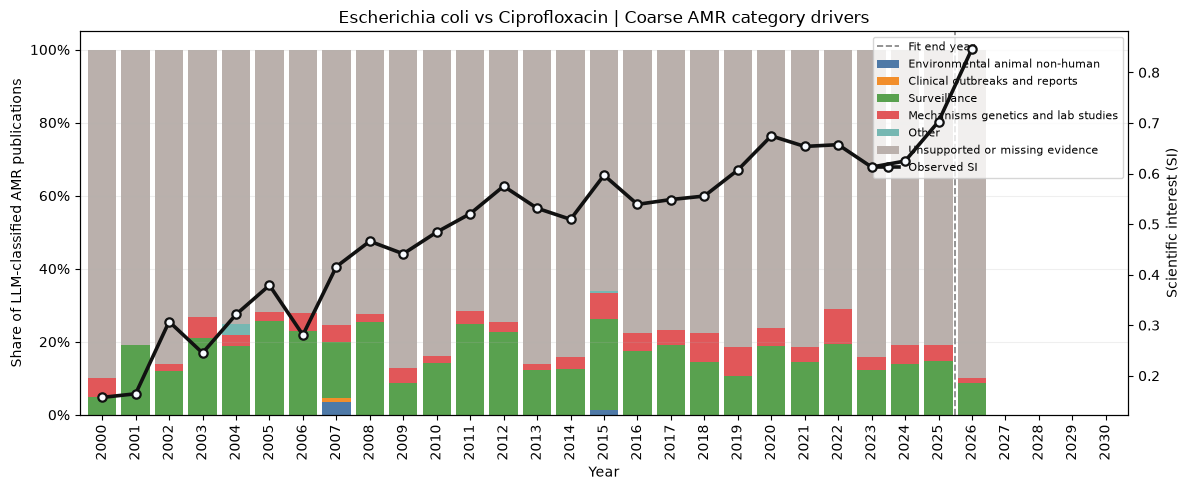

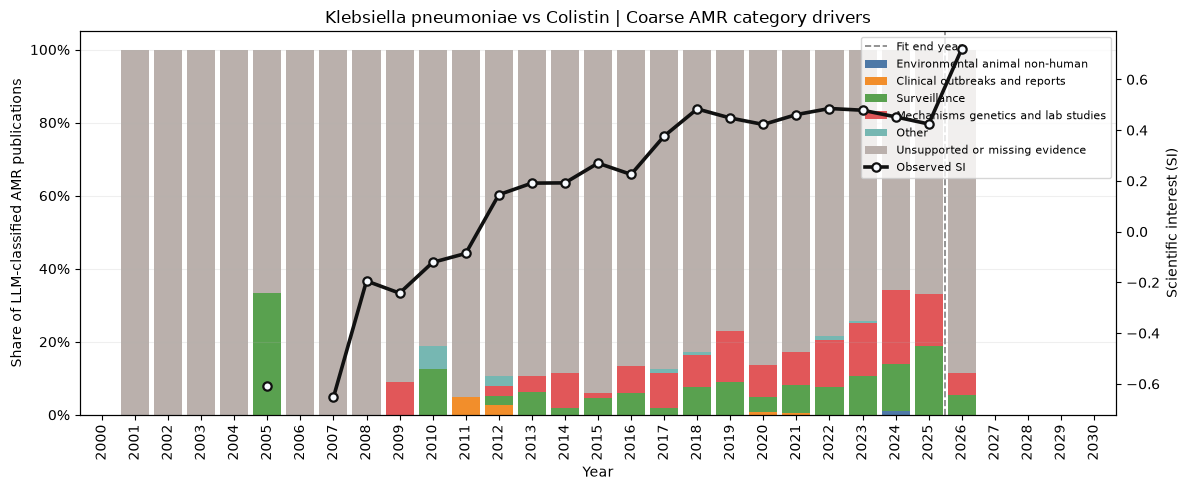

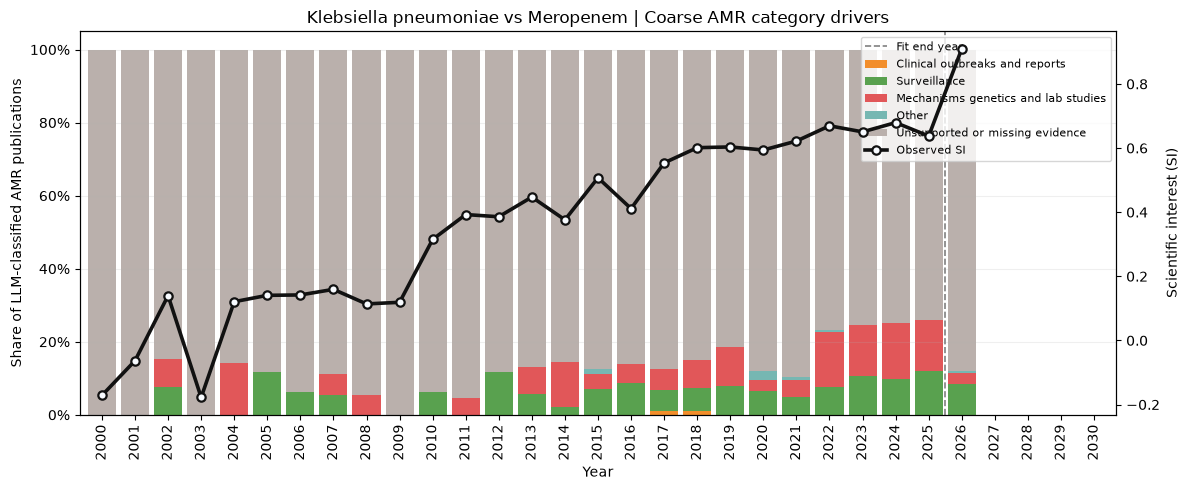

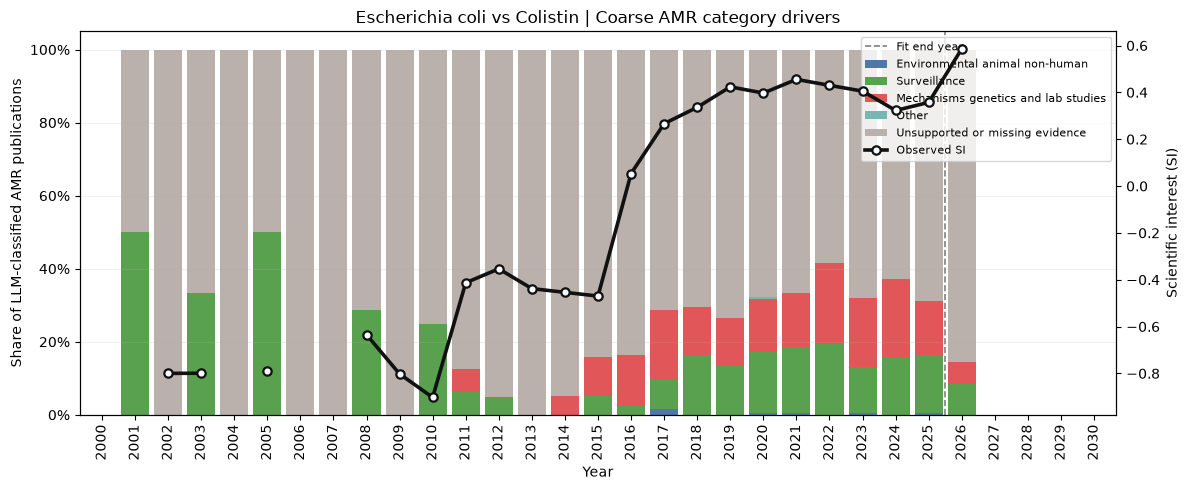

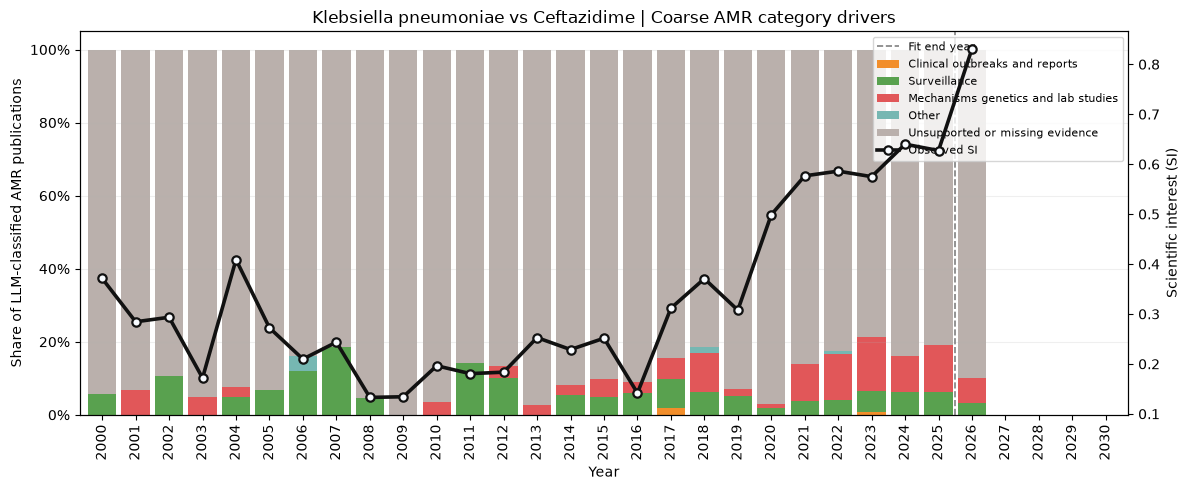

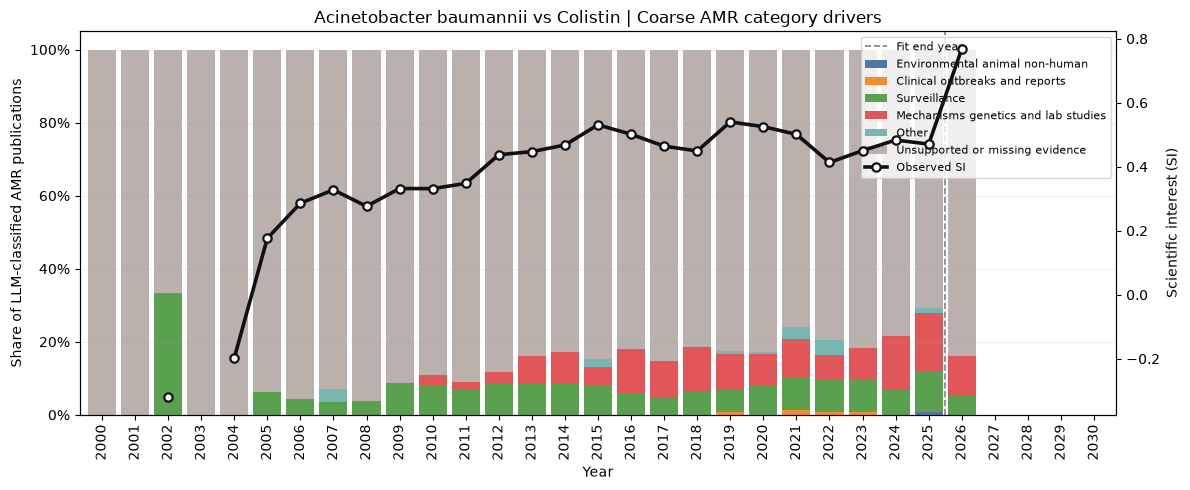

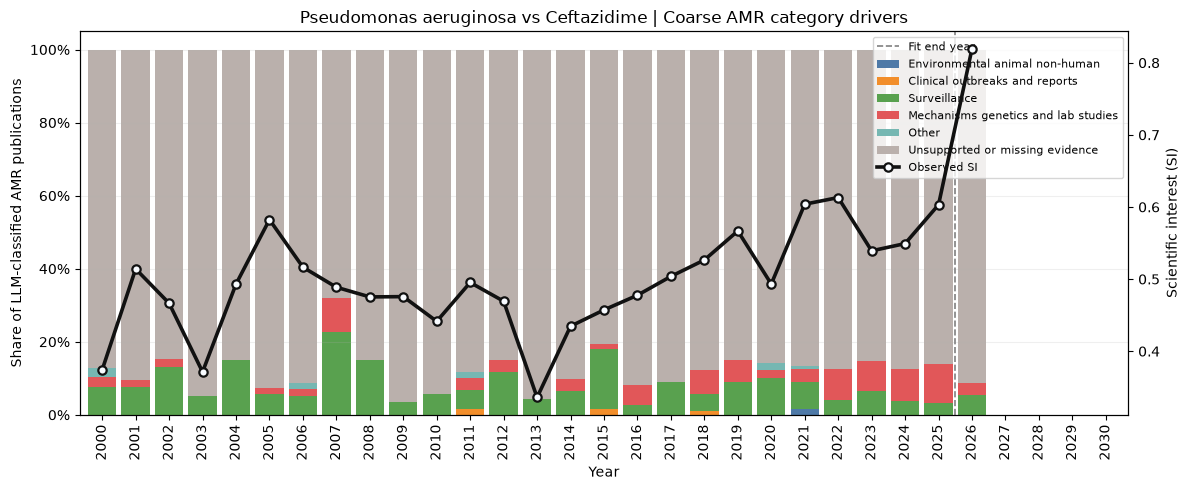

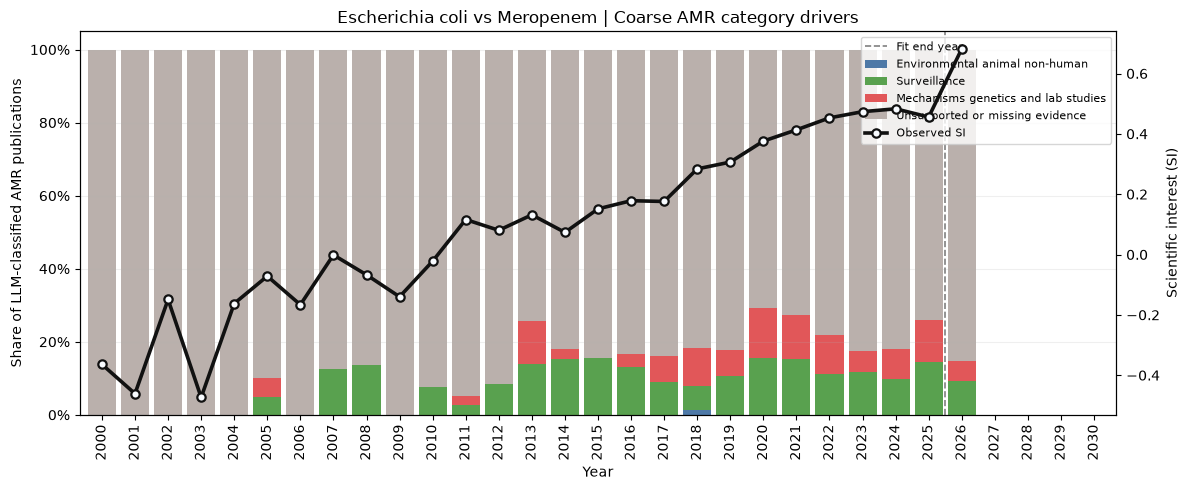

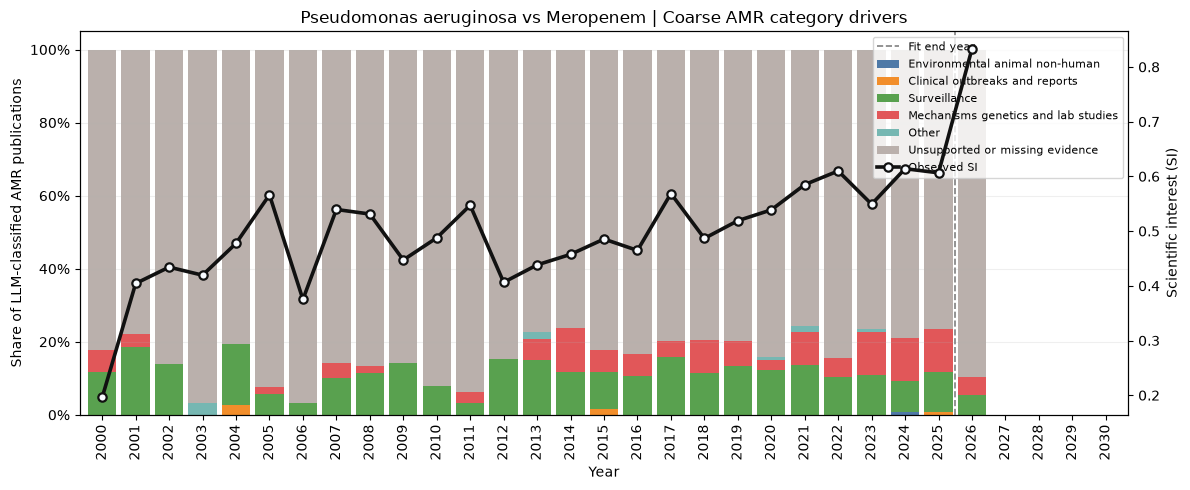

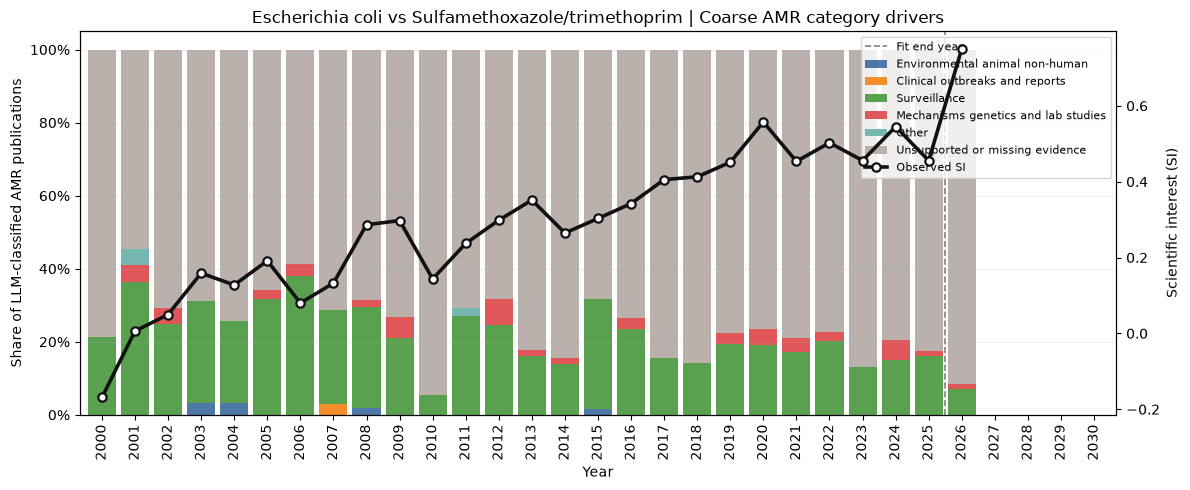

Saved 80 coarse category driver plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved GLASS driver plots: 80 -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_driver_plots


In [7]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=driver_pairs_df,
    output_dir=GLASS_DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=CURVE_FIT_END_YEAR,
    max_plots=len(driver_pairs_df),
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS driver plots: {saved_driver_plots:,} -> {GLASS_DRIVER_PLOT_DIR}")

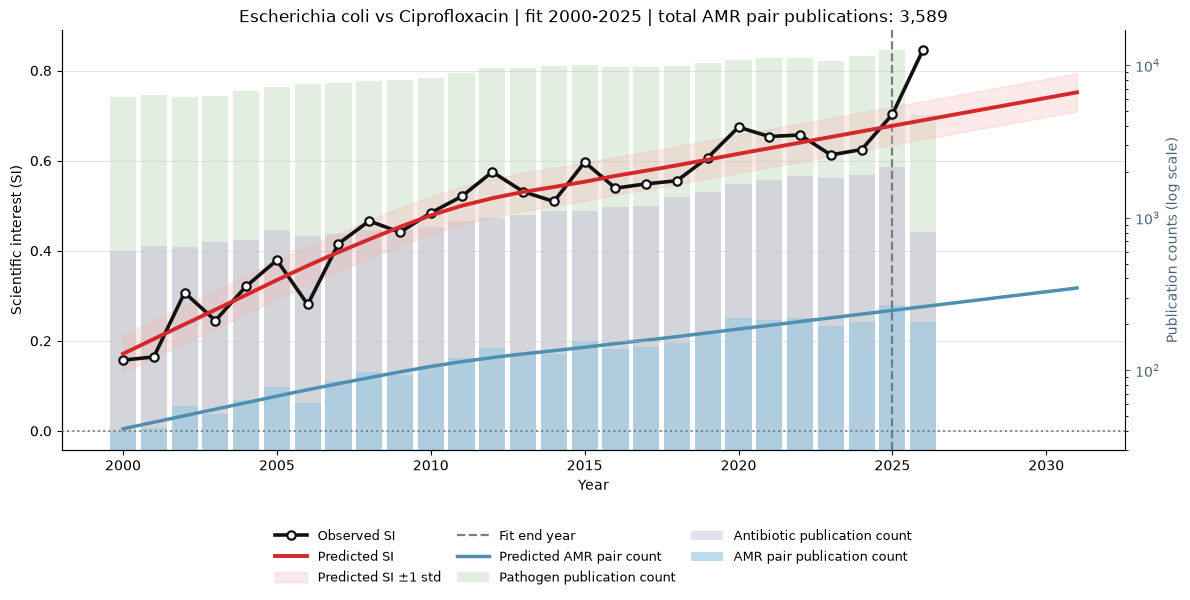

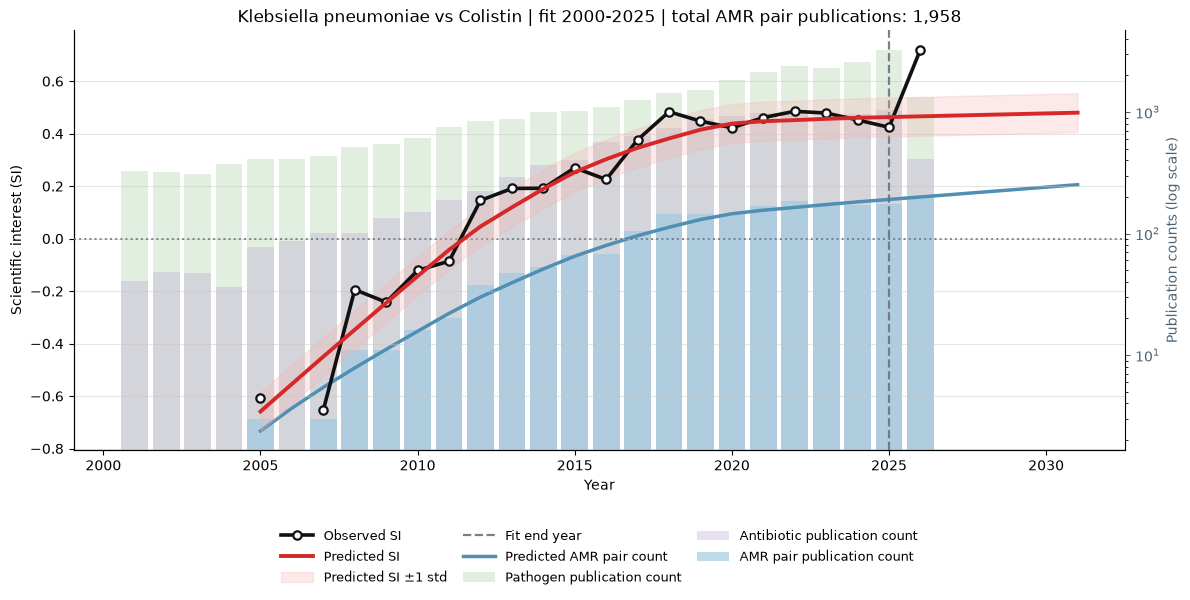

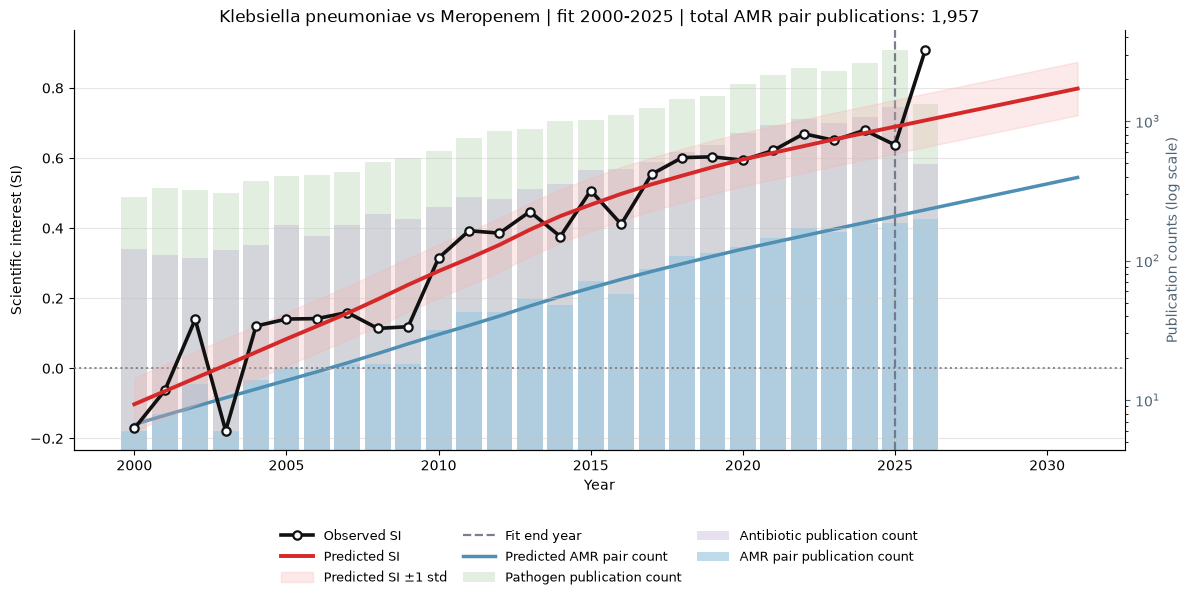

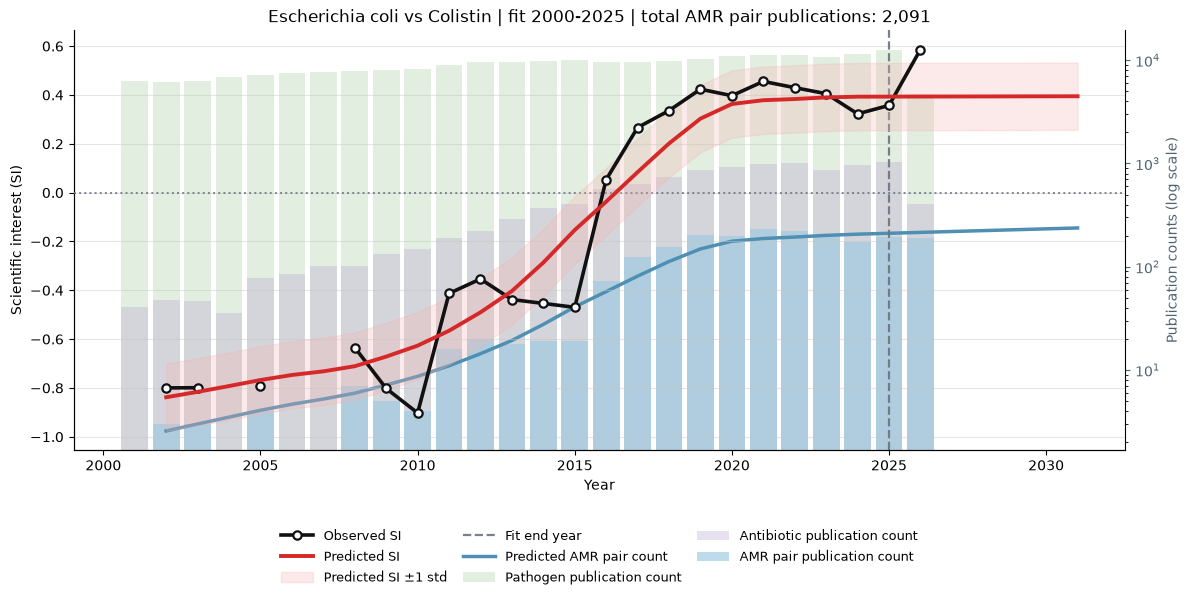

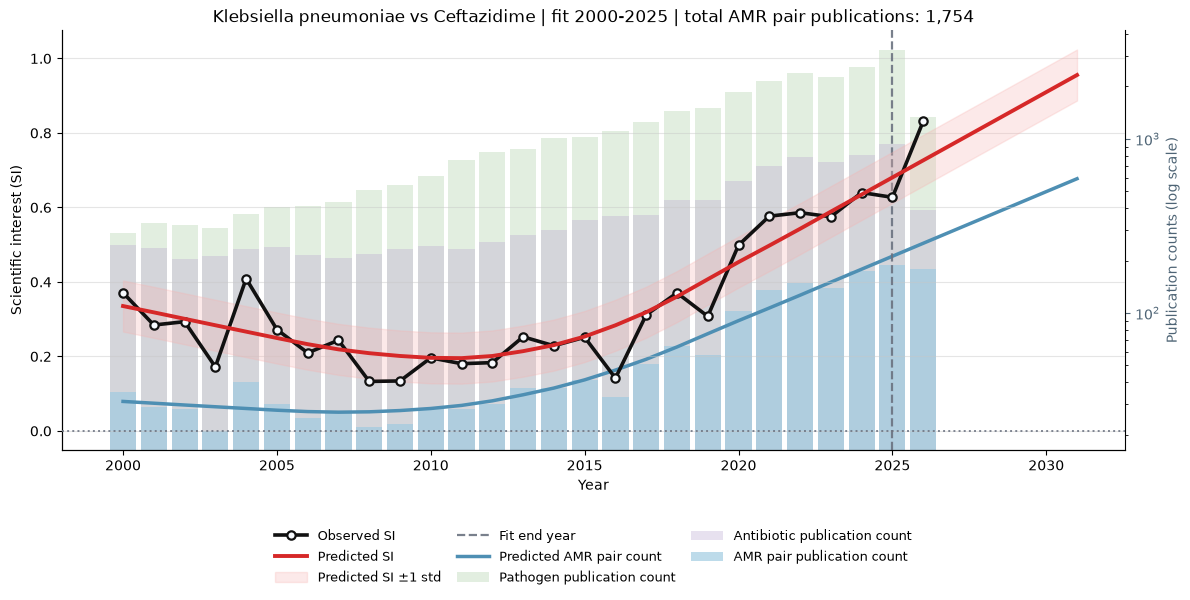

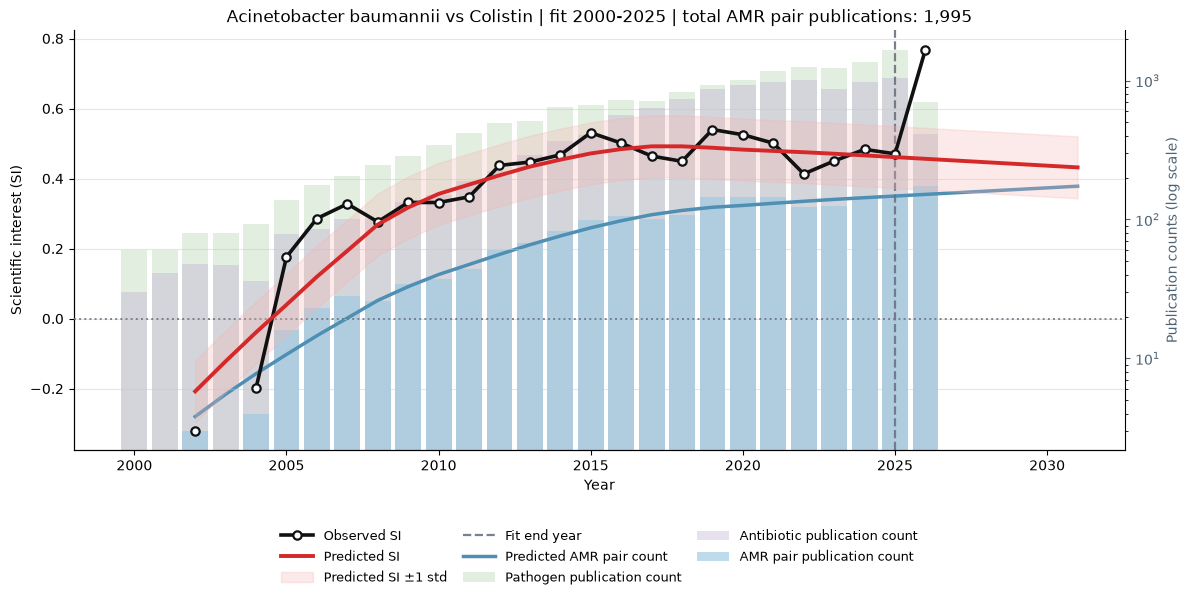

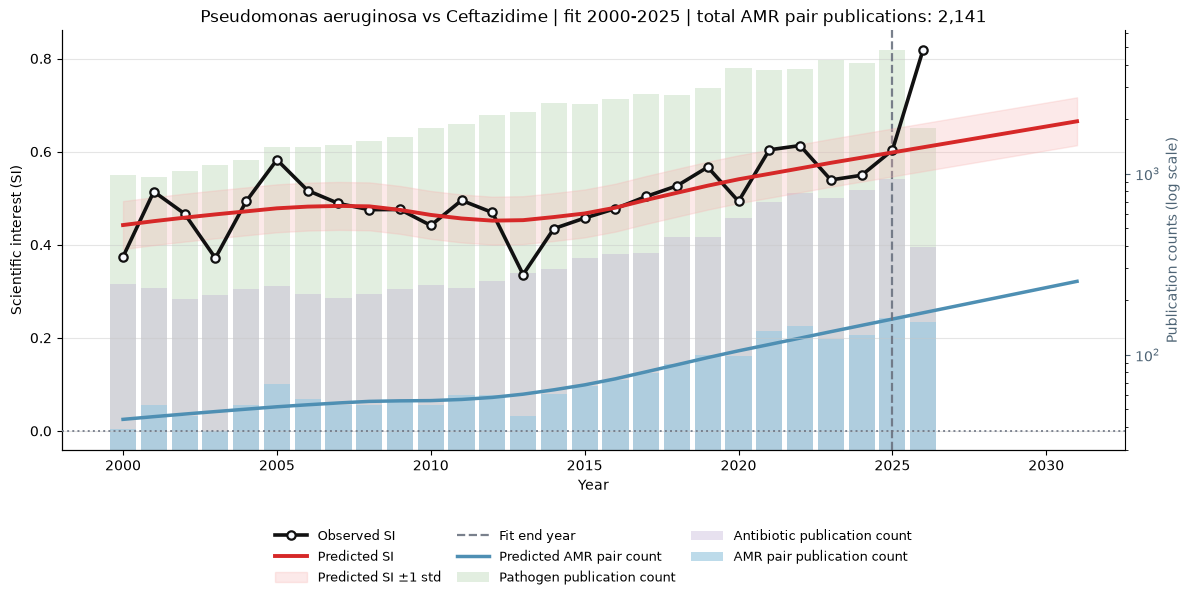

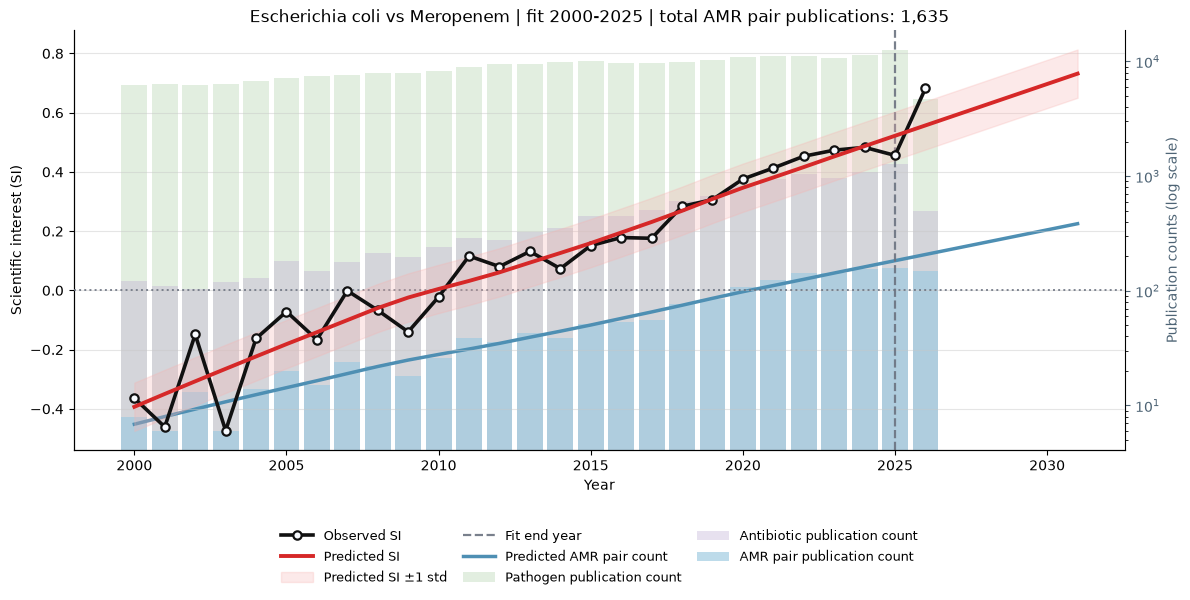

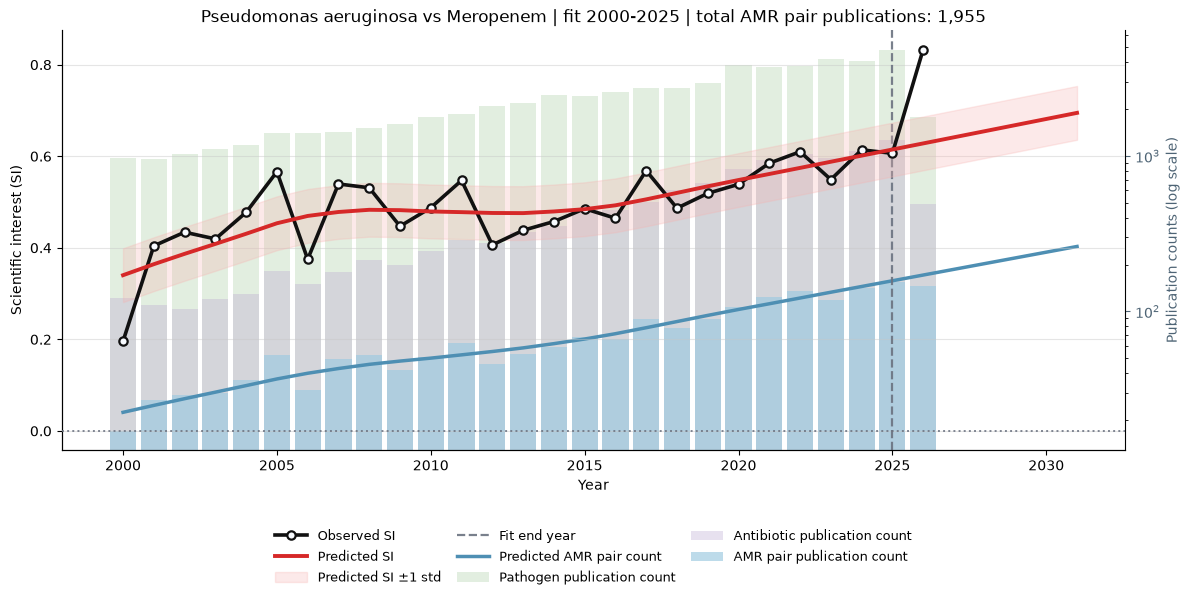

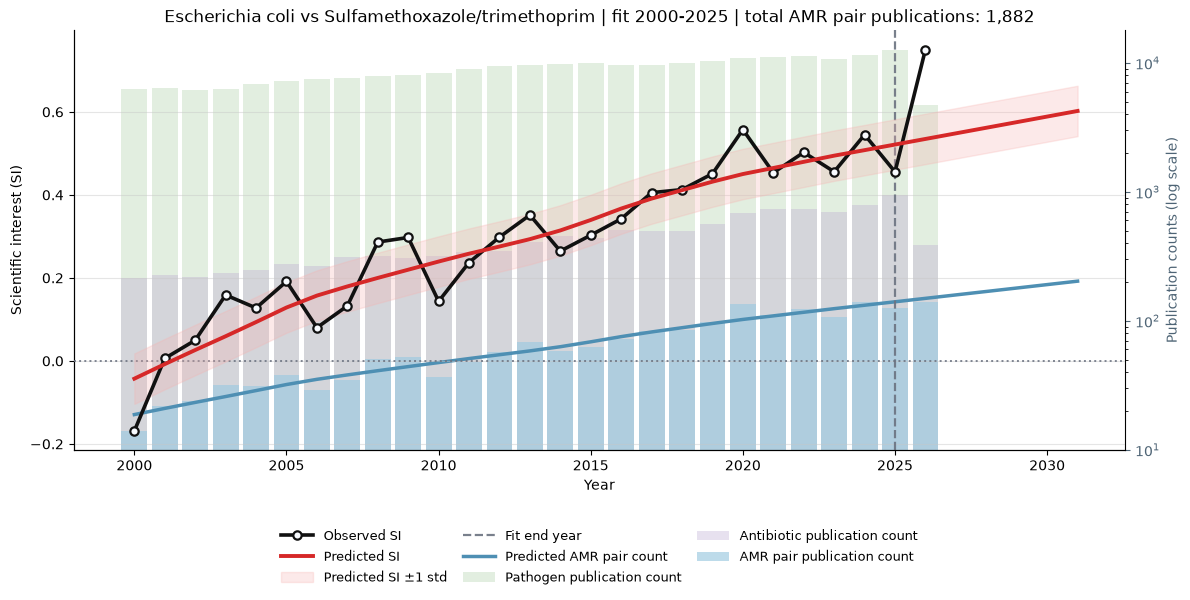

Skipping Salmonella enterica vs Meropenem: Need at least 10 years with valid AMR pair counts between 2000 and 2025; found 8.
Skipping Shigella sonnei vs Azithromycin: Need at least 10 years with valid AMR pair counts between 2000 and 2025; found 8.
Saved 78 plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots
Skipped 2 plots because they lacked enough valid yearly AMR counts.
Displayed 10 plots inline.
Saved GLASS SI plots: 78 -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/glass_yearly_si_plots


In [8]:
saved_si_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=glass_plot_pairs_df,
    output_dir=GLASS_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=len(glass_plot_pairs_df),
    loess_frac=LOESS_FRAC,
    loess_degree=LOESS_DEGREE,
    tail_damping_years=TAIL_DAMPING_YEARS,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

print(f"Saved GLASS SI plots: {saved_si_plots:,} -> {GLASS_SI_PLOT_DIR}")